# Parametric Drought-Index Insurance Simulator: Eastern Rwanda Maize
Data and modelling pipeline for the capstone proposal (Chapter Three).

### How this notebook maps to the ML track

| Requirement | Where |
|---|---|
| Data engineering | Sections 3–6 (satellite extraction, NISR yields) and the **Data engineering summary** at the end of Section 6 |
| Data visualization | Section 7: distributions, relationships, **correlation matrix**, **yields by district**, seasonal profiles, peak-NDVI sensitivity |
| Model architecture | Section 8: model comparison and **Model architecture** (pipeline, penalty, optimisation, tuning curve) |
| Initial performance metrics | Section 8 (RMSE, MAE, predictive R² under two validation schemes) and Section 9 (**accuracy, precision, recall, F1, confusion matrix** for the payout decision) |
| Deployment option | Section 12: FastAPI backend with Swagger UI and the Next.js dashboard |

## 1. Setup

In [ ]:
!pip install -q pyreadstat

import os, json, csv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from sklearn.model_selection import LeaveOneOut, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.linear_model import RidgeCV, LassoCV, LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error

import ee
ee.Authenticate()
ee.Initialize(project='rwanda-drought-index')

from google.colab import drive
drive.mount('/content/drive')

DATA_DIR   = '/content/drive/MyDrive/parametric-drought-simulator'
NISR_DIR   = f'{DATA_DIR}/nisr'
SAT_CSV    = f'{DATA_DIR}/satellite_district_seasons.csv'
YIELD_CSV  = f'{DATA_DIR}/district_maize_yield.csv'
MODEL_JSON = f'{DATA_DIR}/selected_model.json'
print('Setup complete')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.7/2.7 MB 35.7 MB/s eta 0:00:00
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Setup complete


## 2. Configuration

In [ ]:
DISTRICTS = ['Bugesera', 'Gatsibo', 'Kayonza', 'Kirehe', 'Ngoma', 'Nyagatare', 'Rwamagana']

# Season Y runs from September of Y-1 to February of Y (NISR Season A).
# Critical growth window (to confirm from the JRC crop calendar):
WIN_START_MONTH = 10   # October of Y-1
WIN_END_MONTH   = 12   # December of Y-1

YIELD_SEASONS  = [2022, 2023, 2025]      # may become [2022, 2023, 2024, 2025] after Section 5
CHIRPS_SEASONS = list(range(1982, 2026)) # CHIRPS starts 1981
MODIS_SEASONS  = list(range(2001, 2026)) # MODIS starts 2000

LOW_YIELD_THRESHOLD = -10.0  # % below district average, fixed before seeing results
DROUGHT_YEARS = list(range(2003, 2007)) + list(range(2013, 2018))  # Niyonsenga et al. (2024)

NISR_FILES = {2022: 'season_a_2022.sav', 2023: 'season_a_2023.csv',
              2024: 'season_a_2024.csv', 2025: 'season_a_2025.csv'}

## 3. Boundaries and satellite datasets
District boundaries: FAO GAUL 2025. Cropland mask: ESA WorldCover (class 40).

In [ ]:
NAME_FIELD = 'GAUL2_NAME'
districts = (ee.FeatureCollection('FAO/GAUL/2025/level2')
             .filter(ee.Filter.eq('ISO3_CODE', 'RWA'))
             .filter(ee.Filter.inList(NAME_FIELD, DISTRICTS)))
found = districts.aggregate_array(NAME_FIELD).getInfo()
assert len(found) == 7, f'Only found: {found}'
print('All seven districts found')

cropland = ee.ImageCollection('ESA/WorldCover/v200').first().select('Map').eq(40)
chirps = ee.ImageCollection('UCSB-CHG/CHIRPS/PENTAD').select('precipitation')
modis  = ee.ImageCollection('MODIS/061/MOD13Q1')

def window(y):
    y = ee.Number(y)
    start = ee.Date.fromYMD(y.subtract(1), WIN_START_MONTH, 1)
    end   = ee.Date.fromYMD(y.subtract(1), WIN_END_MONTH, 1).advance(1, 'month')
    return start, end

def chirps_season(y):
    start, end = window(y)
    img = chirps.filterDate(start, end).sum().rename('value')   # total rainfall in the window
    return img.updateMask(cropland).set('season', y)

def modis_season(y):
    start, end = window(y)
    def clean(img):
        good = img.select('SummaryQA').lte(1)   # keep good and marginal pixels
        return img.select('NDVI').multiply(0.0001).updateMask(good)
    img = modis.filterDate(start, end).map(clean).mean().rename('value')
    return img.updateMask(cropland).set('season', y)

def extract(season_fn, seasons, scale, name):
    col = ee.ImageCollection(ee.List(seasons).map(season_fn))
    def reduce(img):
        fc = img.reduceRegions(collection=districts, reducer=ee.Reducer.mean(), scale=scale)
        return fc.map(lambda f: f.set('season', img.get('season')))
    feats = col.map(reduce).flatten().getInfo()['features']
    return pd.DataFrame([{'district': f['properties'][NAME_FIELD],
                          'season': int(f['properties']['season']),
                          name: f['properties'].get('mean')} for f in feats])

All seven districts found


## 4. Satellite extraction and anomalies
Extracted once, then loaded from Drive.

In [ ]:
if os.path.exists(SAT_CSV):
    sat = pd.read_csv(SAT_CSV)
    print('Loaded cached satellite data:', sat.shape)
else:
    rain = extract(chirps_season, CHIRPS_SEASONS, 1000, 'rain_mm')
    ndvi = extract(modis_season, MODIS_SEASONS, 250, 'ndvi')
    sat = rain.merge(ndvi, on=['district', 'season'], how='left')
    sat.to_csv(SAT_CSV, index=False)
    print('Extracted and saved:', sat.shape)

def zscore(s):
    return (s - s.mean()) / s.std(ddof=1)

sat['rain_z'] = sat.groupby('district')['rain_mm'].transform(zscore)
sat['ndvi_z'] = sat.groupby('district')['ndvi'].transform(zscore)

print('\nWeather in the yield seasons (province averages):')
print(sat[sat['season'].between(2022, 2025)].groupby('season')[['rain_mm', 'rain_z', 'ndvi', 'ndvi_z']].mean().round(2))

Loaded cached satellite data: (308, 4)

Weather in the yield seasons (province averages):
        rain_mm  rain_z  ndvi  ndvi_z
season                               
2022     325.65   -0.06  0.61   -0.59
2023     300.39   -0.43  0.63   -0.30
2024     327.77    0.00  0.68    1.25
2025     413.91    1.34  0.62   -0.74


## 5. NISR survey data
Seasonal Agricultural Survey microdata, Season A.
File formats differ by year: 2022 is SPSS, 2023 is comma-separated, 2025 is tab-separated.
2024 is not used: its release omits the maize area and yield variables, and the plot-share
information needed to reconstruct them is not included in the file.

In [ ]:
def load_nisr(path):
    if path.endswith('.sav'):
        return pd.read_spss(path)
    with open(path, encoding='latin-1') as f:
        sep = csv.Sniffer().sniff(''.join(f.readline() for _ in range(5))).delimiter
    return pd.read_csv(path, sep=sep, low_memory=False, encoding='latin-1')

raw = {yr: load_nisr(f'{NISR_DIR}/{NISR_FILES[yr]}') for yr in YIELD_SEASONS}
for yr, d in raw.items():
    print(f'{yr}: {d.shape[0]:,} rows, {d.shape[1]} columns')

2022: 41,589 rows, 101 columns
2023: 39,038 rows, 103 columns
2025: 34,369 rows, 101 columns


## 6. District maize yields
Plots: Eastern Province, maize (CropCategory = 'Maize', which excludes fodder maize), smallholders only.
Area (ha): Harv_area in 2022 and 2023; Crop_Area_ha in 2025 (NISR's own variables).
Production (kg): s2q21 in all years.

In [ ]:
AREA_COL       = {2022: 'Harv_area', 2023: 'Harv_area', 2025: 'Crop_Area_ha'}
NISR_YIELD_COL = {2022: 'yield',     2023: 'yield',     2025: 'Yield'}

def num(s):
    return pd.to_numeric(s, errors='coerce')

def maize_plots(d, yr):
    small = d['s1q7'].astype(str).str.lower().str.startswith('small')
    m = d[(d['s1q1'] == 'East') & (d['CropCategory'] == 'Maize') & small].copy()
    m['district'] = m['s1q2'].astype(str)
    m['area_ha'] = num(m[AREA_COL[yr]])
    m['production_kg'] = num(m['s2q21'])
    return m.dropna(subset=['area_ha', 'production_kg', 'plot_weight'])

plots = {yr: maize_plots(raw[yr], yr) for yr in YIELD_SEASONS}

for yr, m in plots.items():
    gap = (m['production_kg'] - num(m[NISR_YIELD_COL[yr]]) * m['area_ha']).abs()
    print(f'{yr}: {len(m):,} smallholder maize plots | production matches NISR yield for {(gap < 1).mean():.1%}')

print('\nPlots per district:')
print(pd.DataFrame({yr: m['district'].value_counts() for yr, m in plots.items()}).loc[DISTRICTS])

2022: 2,857 smallholder maize plots | production matches NISR yield for 100.0%
2023: 2,941 smallholder maize plots | production matches NISR yield for 100.0%
2025: 2,733 smallholder maize plots | production matches NISR yield for 100.0%

Plots per district:
           2022  2023  2025
district                   
Bugesera    365   322   328
Gatsibo     445   410   435
Kayonza     298   375   302
Kirehe      539   559   505
Ngoma       396   430   402
Nyagatare   363   427   421
Rwamagana   451   418   340


### Calculating weighted district yields

In [ ]:
rows = []
for yr, m in plots.items():
    for dist, g in m.groupby('district'):
        w = g['plot_weight']
        rows.append({'district': dist, 'season': yr,
                     'yield_kg_ha': (w * g['production_kg']).sum() / (w * g['area_ha']).sum(),
                     'plots': len(g)})

yld = pd.DataFrame(rows)
yld = yld[yld['district'].isin(DISTRICTS)].reset_index(drop=True)
assert len(yld) == 21, f'Expected 21 district-seasons, got {len(yld)}'
yld.to_csv(YIELD_CSV, index=False)

print(f'{len(yld)} district-seasons saved\n')
print('District maize yield (kg/ha):')
print(yld.pivot(index='district', columns='season', values='yield_kg_ha').round(0))

21 district-seasons saved

District maize yield (kg/ha):
season       2022    2023    2025
district                         
Bugesera   1420.0   780.0  1729.0
Gatsibo    1543.0  1616.0  2050.0
Kayonza    1079.0  1277.0  1673.0
Kirehe     1071.0  1755.0  2597.0
Ngoma      1727.0  1634.0  2297.0
Nyagatare  2028.0  2944.0  3157.0
Rwamagana  1367.0  1092.0  1739.0


### Combining yields with the satellite anomalies

In [ ]:
yld['yield_anom'] = yld.groupby('district')['yield_kg_ha'].transform(lambda s: 100 * (s - s.mean()) / s.mean())

df = yld.merge(sat[['district', 'season', 'rain_mm', 'ndvi', 'rain_z', 'ndvi_z']],
               on=['district', 'season'], how='left')
assert df[['rain_z', 'ndvi_z']].notna().all().all(), 'Missing satellite values for some district-seasons'

print(f'Modelling dataset: {len(df)} rows\n')
print(df[['district', 'season', 'yield_kg_ha', 'yield_anom', 'rain_z', 'ndvi_z']].round(2).to_string(index=False))

Modelling dataset: 21 rows

 district  season  yield_kg_ha  yield_anom  rain_z  ndvi_z
 Bugesera    2022      1420.14        8.43    0.11   -1.28
  Gatsibo    2022      1543.40      -11.13   -0.20    0.38
  Kayonza    2022      1079.43      -19.63   -0.18   -1.37
   Kirehe    2022      1070.84      -40.76    0.12   -0.99
    Ngoma    2022      1726.86       -8.43    0.07   -0.56
Nyagatare    2022      2028.25      -25.15   -0.36    0.16
Rwamagana    2022      1366.72       -2.32   -0.01   -0.43
 Bugesera    2023       779.80      -40.46   -0.50   -0.08
  Gatsibo    2023      1616.49       -6.92   -0.52   -0.63
  Kayonza    2023      1277.05       -4.92   -0.48   -0.05
   Kirehe    2023      1755.28       -2.90   -0.22    0.18
    Ngoma    2023      1633.65      -13.37   -0.60   -0.00
Nyagatare    2023      2943.84        8.64   -0.03    0.12
Rwamagana    2023      1091.58      -21.98   -0.68   -1.65
 Bugesera    2025      1729.30       32.03    1.43    0.09
  Gatsibo    2025      2050.

### Data engineering summary

How the raw data becomes the 21-row modelling table:

| Step | Satellite (CHIRPS rainfall, MODIS NDVI) | NISR Seasonal Agricultural Survey |
|---|---|---|
| Source | Google Earth Engine: `UCSB-CHG/CHIRPS/PENTAD`, `MODIS/061/MOD13Q1` | Season A microdata, 2022, 2023, 2025 (2024 excluded: data-quality issue) |
| Spatial | Clipped to the 7 district polygons (FAO GAUL 2025, level 2); masked to cropland (ESA WorldCover class 40) | Filtered to Eastern Province, smallholder plots, maize |
| Temporal | Critical window October–December before each Season A harvest; rainfall summed, NDVI averaged; MODIS pixels with poor quality flags removed | One record per plot for the season |
| Aggregation | Mean over cropland pixels → one value per district-season (1982–2025 rainfall, 2001–2025 NDVI) | Survey-weighted yield = Σ(weight × production) / Σ(weight × area) per district-season |
| Feature / target | z-score against each district's own history → `rain_z`, `ndvi_z` | % deviation from the district's mean yield → `yield_anom` |
| Result | 308 district-seasons of satellite data (175 with both inputs) | 41,589 / 39,038 / 34,369 survey rows → 2,857 / 2,941 / 2,733 maize plots → 21 district-seasons |

The model is trained on the 21 district-seasons where both sides exist. The other 154 satellite-only
district-seasons are used for the drought-year backtest in Section 10.

## 7. Exploratory data analysis
The five checks described in Section 3.8 of the proposal.

### completeness and distributions

Missing values: 0

Summary statistics:
       yield_kg_ha  yield_anom  rain_mm   ndvi  rain_z  ndvi_z
count        21.00       21.00    21.00  21.00   21.00   21.00
mean       1741.69        0.00   346.65   0.62    0.28   -0.54
std         609.67       23.03    53.37   0.05    0.81    0.63
min         779.80      -40.76   282.94   0.51   -0.68   -1.65
25%        1366.72      -13.37   303.12   0.58   -0.36   -1.00
50%        1672.95       -2.90   330.65   0.62   -0.01   -0.43
75%        2028.25       18.05   386.80   0.66    1.21   -0.00
max        3157.33       43.66   448.40   0.69    1.82    0.38


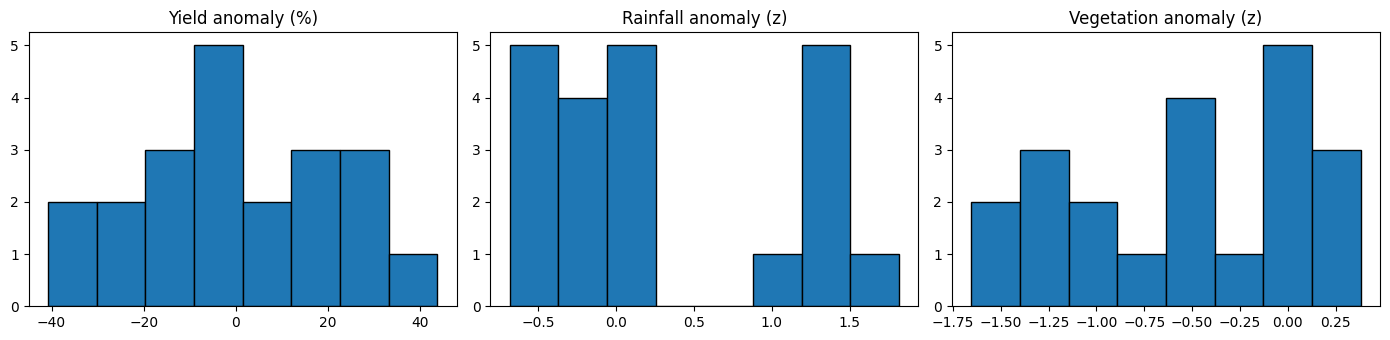

In [ ]:
print('Missing values:', int(df.isna().sum().sum()))
print('\nSummary statistics:')
print(df[['yield_kg_ha', 'yield_anom', 'rain_mm', 'ndvi', 'rain_z', 'ndvi_z']].describe().round(2))

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, col, label in zip(axes, ['yield_anom', 'rain_z', 'ndvi_z'],
                          ['Yield anomaly (%)', 'Rainfall anomaly (z)', 'Vegetation anomaly (z)']):
    ax.hist(df[col], bins=8, edgecolor='black')
    ax.set_title(label)
plt.tight_layout(); plt.show()

### Relationships

rain_z vs yield anomaly: Pearson r = 0.80 (p = 0.000), Spearman rho = 0.74 (p = 0.000)
ndvi_z vs yield anomaly: Pearson r = -0.07 (p = 0.765), Spearman rho = -0.07 (p = 0.750)

Correlation between the two inputs: -0.19


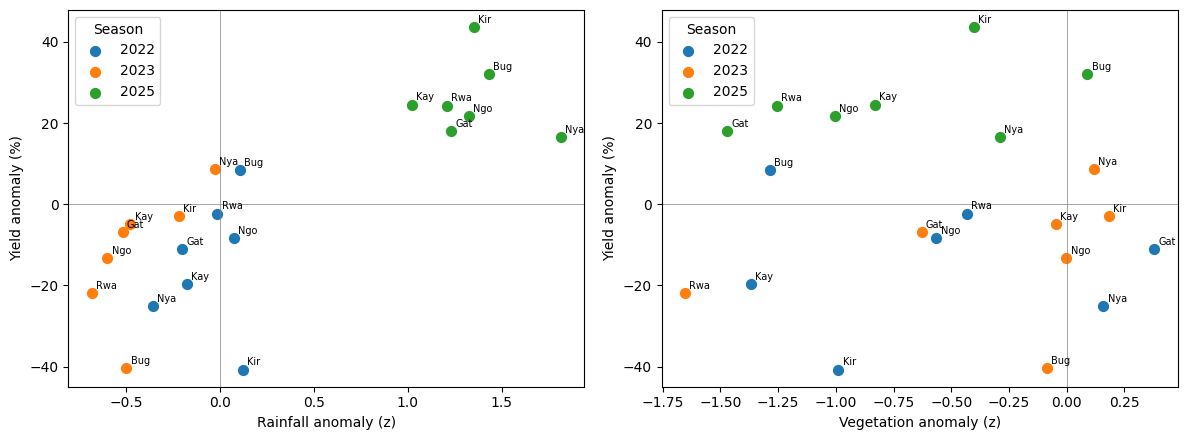

In [ ]:
for feat in ['rain_z', 'ndvi_z']:
    r, p_r = stats.pearsonr(df[feat], df['yield_anom'])
    rho, p_s = stats.spearmanr(df[feat], df['yield_anom'])
    print(f'{feat} vs yield anomaly: Pearson r = {r:.2f} (p = {p_r:.3f}), Spearman rho = {rho:.2f} (p = {p_s:.3f})')
r_in, _ = stats.pearsonr(df['rain_z'], df['ndvi_z'])
print(f'\nCorrelation between the two inputs: {r_in:.2f}')

colors = {2022: 'tab:blue', 2023: 'tab:orange', 2025: 'tab:green'}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, feat, label in zip(axes, ['rain_z', 'ndvi_z'], ['Rainfall anomaly (z)', 'Vegetation anomaly (z)']):
    for yr, g in df.groupby('season'):
        ax.scatter(g[feat], g['yield_anom'], color=colors[yr], label=str(yr), s=50)
        for _, row in g.iterrows():
            ax.annotate(row['district'][:3], (row[feat], row['yield_anom']), fontsize=7, xytext=(3, 3), textcoords='offset points')
    ax.axhline(0, lw=0.5, color='grey'); ax.axvline(0, lw=0.5, color='grey')
    ax.set_xlabel(label); ax.set_ylabel('Yield anomaly (%)'); ax.legend(title='Season')
plt.tight_layout(); plt.show()

In [ ]:
for col in ['yield_anom', 'rain_z', 'ndvi_z']:
    z = (df[col] - df[col].mean()) / df[col].std(ddof=1)
    flagged = df.loc[z.abs() > 2, ['district', 'season', col]]
    print(f'{col}: {len(flagged)} point(s) beyond 2 standard deviations')
    if len(flagged):
        print(flagged.round(2).to_string(index=False))

yield_anom: 0 point(s) beyond 2 standard deviations
rain_z: 0 point(s) beyond 2 standard deviations
ndvi_z: 0 point(s) beyond 2 standard deviations


### Correlation matrix

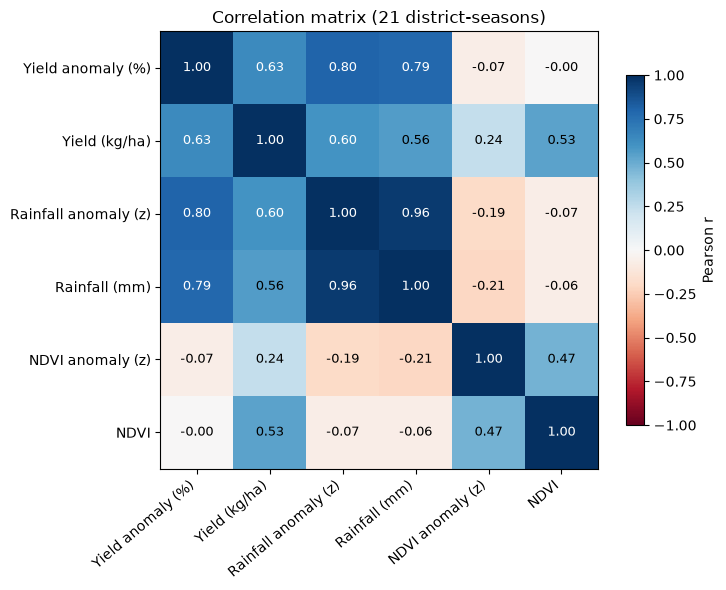

Rainfall anomaly vs yield anomaly: r = 0.80
NDVI anomaly vs yield anomaly:     r = -0.07
Rainfall vs NDVI anomaly:          r = -0.19 (low, so the inputs are not collinear)


In [ ]:
# Correlation matrix of the modelling variables (Pearson)
cols = ['yield_anom', 'yield_kg_ha', 'rain_z', 'rain_mm', 'ndvi_z', 'ndvi']
labels = ['Yield anomaly (%)', 'Yield (kg/ha)', 'Rainfall anomaly (z)', 'Rainfall (mm)',
          'NDVI anomaly (z)', 'NDVI']
corr = df[cols].corr()

fig, ax = plt.subplots(figsize=(7.5, 6))
im = ax.imshow(corr, cmap='RdBu', vmin=-1, vmax=1)
ax.set_xticks(range(len(cols)), labels, rotation=40, ha='right')
ax.set_yticks(range(len(cols)), labels)
for i in range(len(cols)):
    for j in range(len(cols)):
        v = corr.iloc[i, j]
        ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=9,
                color='white' if abs(v) > 0.6 else 'black')
fig.colorbar(im, ax=ax, shrink=0.8, label='Pearson r')
ax.set_title('Correlation matrix (21 district-seasons)')
plt.tight_layout(); plt.show()

print(f"Rainfall anomaly vs yield anomaly: r = {corr.loc['rain_z', 'yield_anom']:.2f}")
print(f"NDVI anomaly vs yield anomaly:     r = {corr.loc['ndvi_z', 'yield_anom']:.2f}")
print(f"Rainfall vs NDVI anomaly:          r = {corr.loc['rain_z', 'ndvi_z']:.2f} (low, so the inputs are not collinear)")

### Yield by district and season

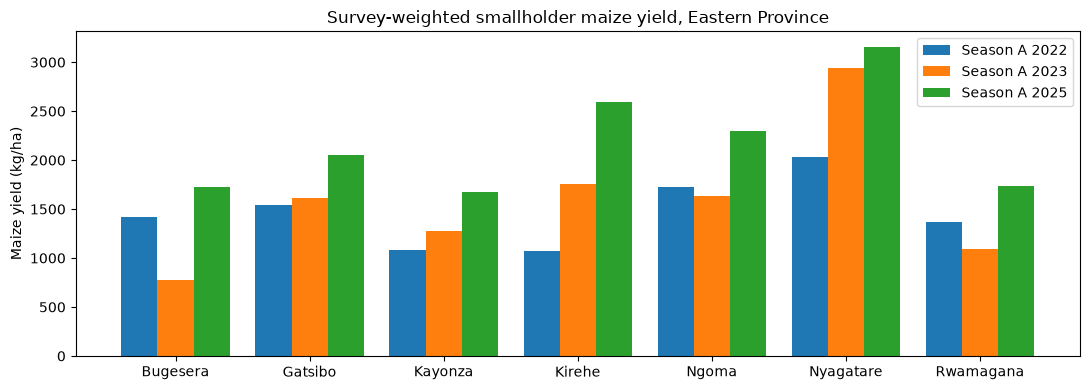

Province-wide mean yield by season (kg/ha):
season
2022    1462.0
2023    1585.0
2025    2177.0


In [ ]:
# Maize yield by district and season: the target before it is turned into an anomaly
pivot = df.pivot(index='district', columns='season', values='yield_kg_ha')

fig, ax = plt.subplots(figsize=(11, 4))
width = 0.27
for k, season in enumerate(pivot.columns):
    ax.bar(np.arange(len(pivot)) + (k - 1) * width, pivot[season], width, label=f'Season A {season}')
ax.set_xticks(range(len(pivot)), pivot.index)
ax.set_ylabel('Maize yield (kg/ha)')
ax.set_title('Survey-weighted smallholder maize yield, Eastern Province')
ax.legend()
plt.tight_layout(); plt.show()

print('Province-wide mean yield by season (kg/ha):')
print(pivot.mean().round(0).to_string())

### Seasonal patterns and cloud cover (EDA check 3)

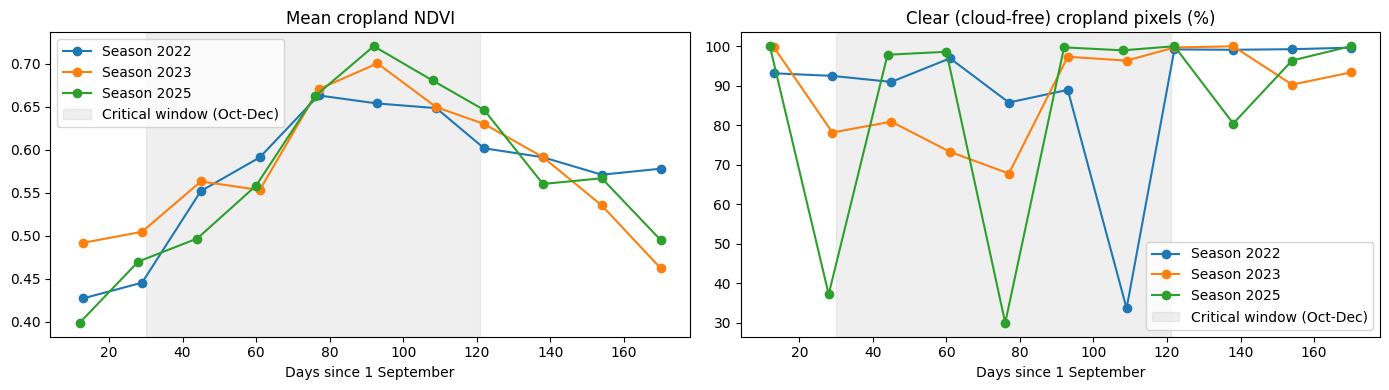

In [ ]:
province = districts.union().geometry()

def season_profile(season_year):
    start = ee.Date.fromYMD(season_year - 1, 9, 1)
    end   = ee.Date.fromYMD(season_year, 3, 1)
    def one(img):
        valid = img.select('SummaryQA').lte(1)
        ndvi = img.select('NDVI').multiply(0.0001).updateMask(valid).updateMask(cropland)
        clear = valid.updateMask(cropland)
        stats_ = (ndvi.reduceRegion(ee.Reducer.mean(), province, 250, maxPixels=1e10)
                  .combine(clear.reduceRegion(ee.Reducer.mean(), province, 250, maxPixels=1e10)))
        return ee.Feature(None, {'date': img.date().format('YYYY-MM-dd'),
                                 'ndvi': stats_.get('NDVI'), 'clear_share': stats_.get('SummaryQA')})
    feats = ee.FeatureCollection(modis.filterDate(start, end).map(one)).getInfo()['features']
    return pd.DataFrame([f['properties'] for f in feats])

profiles = {y: season_profile(y) for y in YIELD_SEASONS}

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for y, p in profiles.items():
    day = (pd.to_datetime(p['date']) - pd.Timestamp(f'{y-1}-09-01')).dt.days
    axes[0].plot(day, p['ndvi'], marker='o', label=f'Season {y}')
    axes[1].plot(day, 100 * p['clear_share'], marker='o', label=f'Season {y}')
for ax, t in zip(axes, ['Mean cropland NDVI', 'Clear (cloud-free) cropland pixels (%)']):
    ax.axvspan(30, 121, alpha=0.12, color='grey', label='Critical window (Oct-Dec)')
    ax.set_title(t); ax.set_xlabel('Days since 1 September'); ax.legend()
plt.tight_layout(); plt.show()

### Sensitivity: peak NDVI
The proposal specifies mean NDVI over the critical window. The seasonal profiles show that 2025 greened later
but peaked higher than 2022 and 2023, which lowers its mean. Peak (maximum) NDVI, as used by Roznik et al. (2022),
is tested alongside mean NDVI. Mean NDVI remains the primary input.

In [ ]:
PEAK_CSV = f'{DATA_DIR}/satellite_ndvi_peak.csv'

def modis_peak_season(y):
    start, end = window(y)
    def clean(img):
        good = img.select('SummaryQA').lte(1)
        return img.select('NDVI').multiply(0.0001).updateMask(good)
    img = modis.filterDate(start, end).map(clean).max().rename('value')   # highest greenness in the window
    return img.updateMask(cropland).set('season', y)

if os.path.exists(PEAK_CSV):
    peak = pd.read_csv(PEAK_CSV)
    print('Loaded cached peak NDVI:', peak.shape)
else:
    peak = extract(modis_peak_season, MODIS_SEASONS, 250, 'ndvi_peak')
    peak.to_csv(PEAK_CSV, index=False)
    print('Extracted and saved:', peak.shape)

peak['ndvi_peak_z'] = peak.groupby('district')['ndvi_peak'].transform(zscore)
df = df.drop(columns=['ndvi_peak', 'ndvi_peak_z'], errors='ignore').merge(
        peak[['district', 'season', 'ndvi_peak', 'ndvi_peak_z']], on=['district', 'season'], how='left')

r, p = stats.pearsonr(df['ndvi_peak_z'], df['yield_anom'])
print(f'\nPeak NDVI vs yield anomaly: Pearson r = {r:.2f} (p = {p:.3f})')
print('For comparison, mean NDVI was r = -0.07')
print(df.groupby('season')[['ndvi_z', 'ndvi_peak_z']].mean().round(2))

Extracted and saved: (175, 3)

Peak NDVI vs yield anomaly: Pearson r = 0.40 (p = 0.074)
For comparison, mean NDVI was r = -0.07
        ndvi_z  ndvi_peak_z
season                     
2022     -0.59        -0.87
2023     -0.30        -0.15
2025     -0.74         0.42


## 8. Model comparison
Models: Ridge, Lasso, quadratic OLS, and a mean-only baseline. Ridge and Lasso tune their penalty with an
inner leave-one-out loop on the training data only (nested cross-validation).
Validation: leave-one-out (as specified in the proposal) and leave-one-season-out (stricter: predicts an unseen year).
Main inputs: rain_z and ndvi_z (mean NDVI). Sensitivity: rain_z and ndvi_peak_z (peak NDVI).

In [ ]:
from sklearn.model_selection import LeaveOneGroupOut

def add_squares(X):
    return np.hstack([X, X ** 2])

alphas = np.logspace(-3, 3, 50)
def make_models():
    return {
        'Baseline (mean)': DummyRegressor(strategy='mean'),
        'Ridge': Pipeline([('scale', StandardScaler()),
                           ('model', RidgeCV(alphas=alphas, cv=LeaveOneOut(), scoring='neg_mean_squared_error'))]),
        'Lasso': Pipeline([('scale', StandardScaler()),
                           ('model', LassoCV(alphas=alphas, cv=LeaveOneOut(), max_iter=50000))]),
        'Quadratic OLS': Pipeline([('squares', FunctionTransformer(add_squares)),
                                   ('model', LinearRegression())]),
    }

def evaluate(features):
    X = df[features].to_numpy(); y = df['yield_anom'].to_numpy()
    rows, preds = [], {}
    for scheme, cv in [('Leave-one-out', LeaveOneOut()), ('Leave-one-season-out', LeaveOneGroupOut())]:
        for name, model in make_models().items():
            p = cross_val_predict(model, X, y, cv=cv, groups=df['season'])
            preds[(scheme, name)] = p
            rows.append({'Validation': scheme, 'Model': name,
                         'RMSE': np.sqrt(mean_squared_error(y, p)),
                         'MAE': mean_absolute_error(y, p),
                         'Predictive R2': 1 - np.sum((y - p) ** 2) / np.sum((y - y.mean()) ** 2)})
    return pd.DataFrame(rows).set_index(['Validation', 'Model']).round(2), preds

results_main, preds_main = evaluate(['rain_z', 'ndvi_z'])
results_peak, preds_peak = evaluate(['rain_z', 'ndvi_peak_z'])

print('MAIN: rainfall + mean NDVI')
print(results_main)
print('\nSENSITIVITY: rainfall + peak NDVI')
print(results_peak)

/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_split.py:86: UserWarning: The groups parameter is ignored by LeaveOneOut
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_split.py:86: UserWarning: The groups parameter is ignored by LeaveOneOut
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_split.py:86: UserWarning: The groups parameter is ignored by LeaveOneOut
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_split.py:86: UserWarning: The groups parameter is ignored by LeaveOneOut
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_split.py:86: UserWarning: The groups parameter is ignored by LeaveOneOut
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_split.py:86: UserWarning: The groups parameter is ignored by LeaveOneOut
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_split

MAIN: rainfall + mean NDVI
                                       RMSE    MAE  Predictive R2
Validation           Model                                       
Leave-one-out        Baseline (mean)  23.59  19.80          -0.10
                     Ridge            15.19  11.64           0.54
                     Lasso            15.43  11.95           0.53
                     Quadratic OLS    17.56  13.84           0.39
Leave-one-season-out Baseline (mean)  30.39  26.24          -0.83
                     Ridge            26.30  21.73          -0.37
                     Lasso            26.54  21.74          -0.40
                     Quadratic OLS    26.79  22.86          -0.42

SENSITIVITY: rainfall + peak NDVI
                                        RMSE    MAE  Predictive R2
Validation           Model                                        
Leave-one-out        Baseline (mean)   23.59  19.80          -0.10
                     Ridge             15.66  11.88           0.51
          

### Selected model
Ridge regression (rain_z, ndvi_z): lowest leave-one-out error and beats the mean-only baseline.
Under leave-one-season-out validation, no model predicts an unseen season well, a limitation of the
three-season panel reported in the results.

In [ ]:
FEATURES = ['rain_z', 'ndvi_z']
X = df[FEATURES].to_numpy(); y = df['yield_anom'].to_numpy()

best = make_models()['Ridge'].fit(X, y)
ridge = best.named_steps['model']
print(f'Selected penalty strength (alpha): {ridge.alpha_:.3f}')
print('Coefficients (per 1 standard deviation of each input):')
for f, c in zip(FEATURES, ridge.coef_):
    print(f'  {f}: {c:+.2f} percentage points of yield')
print(f'  intercept: {ridge.intercept_:+.2f}')

df['index_loo'] = preds_main[('Leave-one-out', 'Ridge')]
results_main.to_csv(f'{DATA_DIR}/model_results_main.csv')
results_peak.to_csv(f'{DATA_DIR}/model_results_peak.csv')
print('\nResults tables saved to Drive')

Selected penalty strength (alpha): 1.526
Coefficients (per 1 standard deviation of each input):
  rain_z: +17.13 percentage points of yield
  ndvi_z: +1.61 percentage points of yield
  intercept: +0.00

Results tables saved to Drive


### Model architecture

The selected model is a regularised linear regression, chosen because 21 observations cannot support
a model with many free parameters (proposal §3.9). It has no hidden layers or activation functions.

```
rain_z ─┐                                     ┌──────────────────────┐     ┌────────────────────────┐
        ├─► StandardScaler ─► Ridge regression ─► predicted yield change ─► payout rule              │
ndvi_z ─┘   (mean 0, sd 1     (linear, L2 penalty) │ (the drought index, %) │  0 above −7% trigger,  │
             on the 21 rows)                     └──────────────────────┘  linear to 100% at −27% │
                                                                           └────────────────────────┘
```

| Component | Choice |
|---|---|
| Inputs | 2 features: rainfall anomaly `rain_z`, vegetation anomaly `ndvi_z` |
| Preprocessing | `StandardScaler`, so the penalty treats both inputs equally |
| Model | `index = b0 + b1·rain + b2·ndvi` (standardised inputs) |
| Loss | squared error + α·(b1² + b2²) (Ridge / L2 penalty) |
| Optimisation | closed-form least-squares solution (no gradient descent or epochs needed) |
| Hyperparameter | α chosen from 50 values between 0.001 and 1000 by leave-one-out cross-validation on the training rows only (nested inside the outer validation) |
| Output | predicted yield anomaly (%), which is the drought index |
| Decision layer | trigger −7% and exit −27%, chosen in Section 9 |

The cell below shows the fitted pipeline, the learned weights, and how the validation error changes
with α.

Pipeline: scale (StandardScaler) -> model (RidgeCV)
Scaler mean: [ 0.282 -0.542], scale: [0.792 0.613]
index = 0.00 +17.13 x rain (standardised) +1.61 x ndvi (standardised)
Selected alpha: 1.526


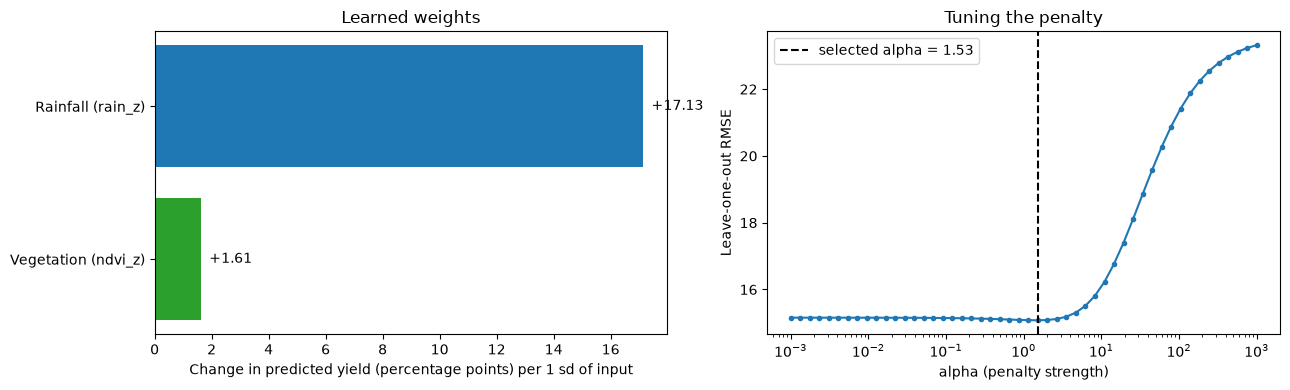

Rainfall carries 91% of the model weight, vegetation 9%.


In [ ]:
print('Pipeline:', ' -> '.join(f'{name} ({type(step).__name__})' for name, step in best.steps))
print(f'Scaler mean: {best.named_steps["scale"].mean_.round(3)}, scale: {best.named_steps["scale"].scale_.round(3)}')
b0, (b1, b2) = round(ridge.intercept_, 2) + 0.0, ridge.coef_
print(f'index = {b0:.2f} {b1:+.2f} x rain (standardised) {b2:+.2f} x ndvi (standardised)')
print(f'Selected alpha: {ridge.alpha_:.3f}')

# Validation error for each alpha (leave-one-out, same folds as the tuning)
from sklearn.linear_model import Ridge
curve = []
for a in alphas:
    p = cross_val_predict(Pipeline([('scale', StandardScaler()), ('model', Ridge(alpha=a))]),
                          X, y, cv=LeaveOneOut())
    curve.append(np.sqrt(mean_squared_error(y, p)))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].barh(['Vegetation (ndvi_z)', 'Rainfall (rain_z)'], [b2, b1], color=['tab:green', 'tab:blue'])
for v, ypos in zip([b2, b1], [0, 1]):
    axes[0].text(v + 0.3, ypos, f'{v:+.2f}', va='center')
axes[0].set_xlabel('Change in predicted yield (percentage points) per 1 sd of input')
axes[0].set_title('Learned weights')

axes[1].semilogx(alphas, curve, marker='.')
axes[1].axvline(ridge.alpha_, ls='--', color='black', label=f'selected alpha = {ridge.alpha_:.2f}')
axes[1].set_xlabel('alpha (penalty strength)'); axes[1].set_ylabel('Leave-one-out RMSE')
axes[1].set_title('Tuning the penalty'); axes[1].legend()
plt.tight_layout(); plt.show()

share = abs(b1) / (abs(b1) + abs(b2))
print(f'Rainfall carries {share:.0%} of the model weight, vegetation {1 - share:.0%}.')

## 9. Payout trigger, exit, and basis risk
Index = the selected model's predicted yield anomaly (leave-one-out predictions, so thresholds are not fitted to the same data).
Payouts start at the trigger and rise linearly to the exit. A low-yield season is one at least 10% below the district average.

In [ ]:
index = df['index_loo'].to_numpy()
low = df['yield_anom'].to_numpy() <= LOW_YIELD_THRESHOLD
print(f'Low-yield district-seasons: {low.sum()} of {len(df)}\n')

scan = []
for t in np.arange(-1, -31, -1):
    pays = index <= t
    scan.append({'trigger': t,
                 'hit_rate': pays[low].mean(),
                 'false_payout_rate': pays[~low].mean()})
scan = pd.DataFrame(scan)
scan['score'] = scan['hit_rate'] - scan['false_payout_rate']
TRIGGER = float(scan.loc[scan['score'].idxmax(), 'trigger'])
EXIT = TRIGGER - 20.0
best_row = scan.loc[scan['trigger'] == TRIGGER].iloc[0]
print(f'Trigger: {TRIGGER:.0f}% | Exit: {EXIT:.0f}%')
print(f'Hit rate: {best_row.hit_rate:.0%} | False payout rate: {best_row.false_payout_rate:.0%}')

def payout_fraction(v):
    return np.clip((TRIGGER - v) / (TRIGGER - EXIT), 0, 1)

df['payout'] = payout_fraction(df['index_loo'])
df['payout_if_actual'] = payout_fraction(df['yield_anom'])
df['basis_risk'] = (df['payout'] - df['payout_if_actual']).abs()

print('\nBasis risk per district (0 = index pays exactly what the loss justifies, 1 = completely wrong):')
print(df.groupby('district')['basis_risk'].mean().round(2).sort_values(ascending=False).to_string())

print('\nSeason by season:')
print(df[['district', 'season', 'yield_anom', 'index_loo', 'payout', 'payout_if_actual']].round(2).to_string(index=False))

Low-yield district-seasons: 7 of 21

Trigger: -7% | Exit: -27%
Hit rate: 86% | False payout rate: 29%

Basis risk per district (0 = index pays exactly what the loss justifies, 1 = completely wrong):
district
Kirehe       0.38
Kayonza      0.31
Gatsibo      0.26
Bugesera     0.25
Nyagatare    0.25
Ngoma        0.11
Rwamagana    0.03

Season by season:
 district  season  yield_anom  index_loo  payout  payout_if_actual
 Bugesera    2022        8.43      -7.67    0.03              0.00
  Gatsibo    2022      -11.13      -7.45    0.02              0.21
  Kayonza    2022      -19.63     -10.61    0.18              0.63
   Kirehe    2022      -40.76      -1.75    0.00              1.00
    Ngoma    2022       -8.43      -4.36    0.00              0.07
Nyagatare    2022      -25.15     -10.16    0.16              0.91
Rwamagana    2022       -2.32      -6.32    0.00              0.00
 Bugesera    2023      -40.46     -12.78    0.29              1.00
  Gatsibo    2023       -6.92     -18.71    

### Trigger selection
Every whole-number trigger from -1% to -30% is scored by hit rate minus false payout rate on the leave-one-out index. -7% and -10% score the same (0.57); the first maximum, -7%, is kept, which pays in more poor seasons (86% against 71%) at the cost of more false payouts (29% against 21%).

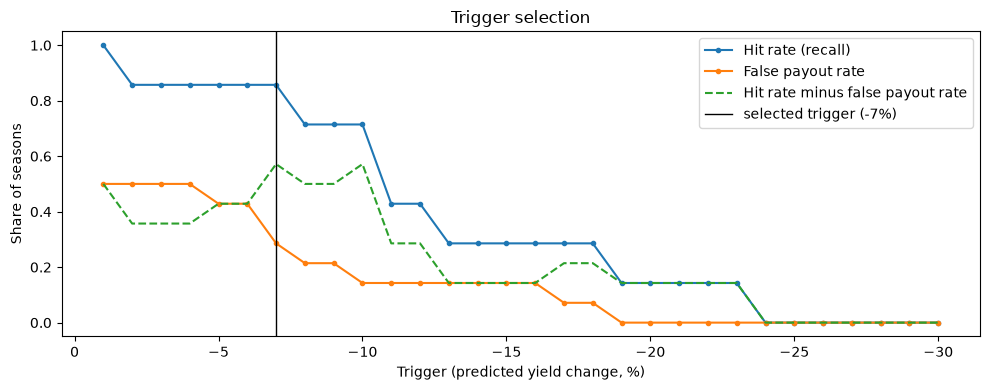

In [ ]:
# How the trigger was chosen: hit rate against false payout rate for every candidate trigger
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(scan['trigger'], scan['hit_rate'], marker='.', label='Hit rate (recall)')
ax.plot(scan['trigger'], scan['false_payout_rate'], marker='.', label='False payout rate')
ax.plot(scan['trigger'], scan['score'], ls='--', label='Hit rate minus false payout rate')
ax.axvline(TRIGGER, color='black', lw=1, label=f'selected trigger ({TRIGGER:.0f}%)')
ax.set_xlabel('Trigger (predicted yield change, %)'); ax.set_ylabel('Share of seasons')
ax.invert_xaxis(); ax.legend(); ax.set_title('Trigger selection')
plt.tight_layout(); plt.show()

### Initial performance metrics of the selected model

Two views of performance, both on leave-one-out predictions (each district-season predicted by a model
that never saw it):

1. **Regression:** how close the predicted yield change is to the actual one (RMSE, MAE, predictive R²,
   reported in Section 8).
2. **Classification:** the insurance decision. A season is a true *poor season* when the actual yield is
   at least 10% below the district average; the index *pays* when its prediction is at or below the
   trigger. This gives accuracy, precision, recall (the hit rate) and F1.

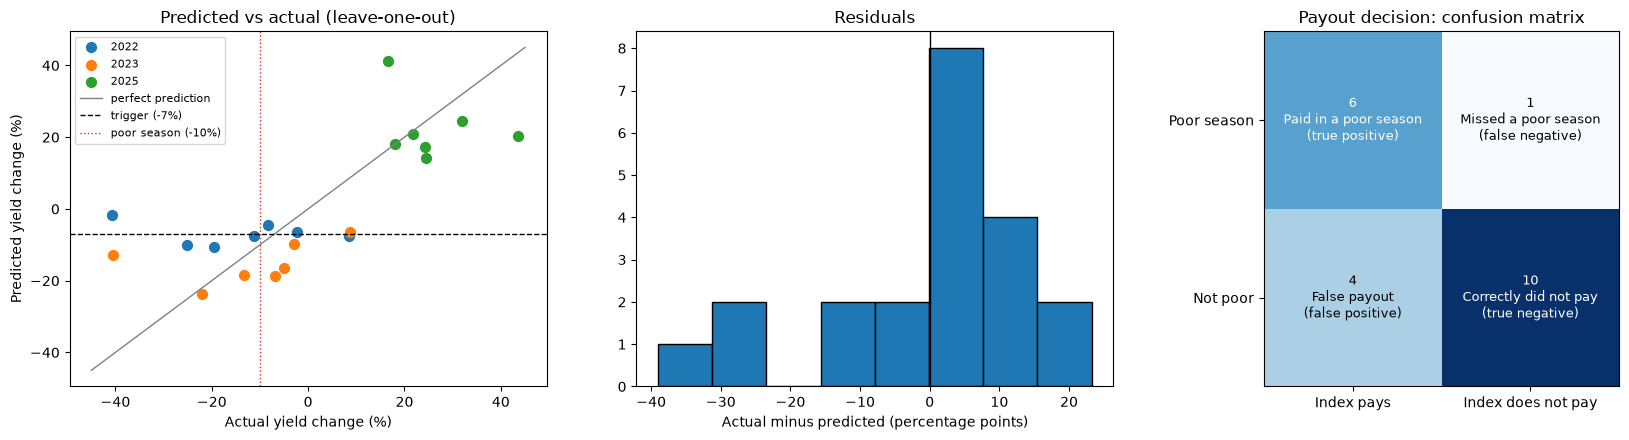

           Metric Value                                                           Meaning
         Accuracy   76% share of the 21 seasons where the pay / no-pay decision was right
        Precision   60%        of the seasons the index paid, share that were really poor
Recall (hit rate)   86%                         of the poor seasons, share the index paid
         F1-score   71%                                   balance of precision and recall
      Specificity   71%      of the normal seasons, share the index correctly did not pay
False payout rate   29%     of the normal seasons, share the index paid (1 - specificity)

Regression (leave-one-out): RMSE 15.19, MAE 11.64, predictive R2 0.54


In [ ]:
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score,
                             precision_score, recall_score)

# 1. Regression view
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
ax = axes[0]
for yr, g in df.groupby('season'):
    ax.scatter(g['yield_anom'], g['index_loo'], s=50, label=str(yr))
lim = [-45, 45]
ax.plot(lim, lim, color='grey', lw=1, label='perfect prediction')
ax.axhline(TRIGGER, ls='--', color='black', lw=1, label=f'trigger ({TRIGGER:.0f}%)')
ax.axvline(LOW_YIELD_THRESHOLD, ls=':', color='tab:red', lw=1, label='poor season (-10%)')
ax.set_xlabel('Actual yield change (%)'); ax.set_ylabel('Predicted yield change (%)')
ax.set_title('Predicted vs actual (leave-one-out)'); ax.legend(fontsize=8)

resid = df['yield_anom'] - df['index_loo']
axes[1].hist(resid, bins=8, edgecolor='black')
axes[1].axvline(0, color='black', lw=1)
axes[1].set_xlabel('Actual minus predicted (percentage points)'); axes[1].set_title('Residuals')

# 2. Classification view: the payout decision
actual_poor = df['yield_anom'] <= LOW_YIELD_THRESHOLD
index_pays = df['index_loo'] <= TRIGGER
cm = confusion_matrix(actual_poor, index_pays, labels=[True, False])
ax = axes[2]
ax.imshow(cm, cmap='Blues')
names = [['Paid in a poor season\n(true positive)', 'Missed a poor season\n(false negative)'],
         ['False payout\n(false positive)', 'Correctly did not pay\n(true negative)']]
for i in range(2):
    for j in range(2):
        ax.text(j, i, f'{cm[i, j]}\n{names[i][j]}', ha='center', va='center', fontsize=9,
                color='white' if cm[i, j] > cm.max() / 2 else 'black')
ax.set_xticks([0, 1], ['Index pays', 'Index does not pay'])
ax.set_yticks([0, 1], ['Poor season', 'Not poor'])
ax.set_title('Payout decision: confusion matrix')
plt.tight_layout(); plt.show()

tn = cm[1, 1]; fp = cm[1, 0]
metrics = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall (hit rate)', 'F1-score',
               'Specificity', 'False payout rate'],
    'Value': [accuracy_score(actual_poor, index_pays), precision_score(actual_poor, index_pays),
              recall_score(actual_poor, index_pays), f1_score(actual_poor, index_pays),
              tn / (tn + fp), fp / (tn + fp)],
    'Meaning': ['share of the 21 seasons where the pay / no-pay decision was right',
                'of the seasons the index paid, share that were really poor',
                'of the poor seasons, share the index paid',
                'balance of precision and recall',
                'of the normal seasons, share the index correctly did not pay',
                'of the normal seasons, share the index paid (1 - specificity)'],
})
metrics['Value'] = metrics['Value'].map('{:.0%}'.format)
print(metrics.to_string(index=False))

reg = results_main.loc[('Leave-one-out', 'Ridge')]
print(f"\nRegression (leave-one-out): RMSE {reg['RMSE']:.2f}, MAE {reg['MAE']:.2f}, "
      f"predictive R2 {reg['Predictive R2']:.2f}")

## 10. Check against documented drought years
The selected model is applied to satellite data for every season since 2001 (not used in training).
Niyonsenga et al. (2024) identify 2003-2006 and 2013-2017 as Rwanda's most severe drought years.
Seasons are compared by the calendar year of their critical window (Season Y's window falls in Y-1).

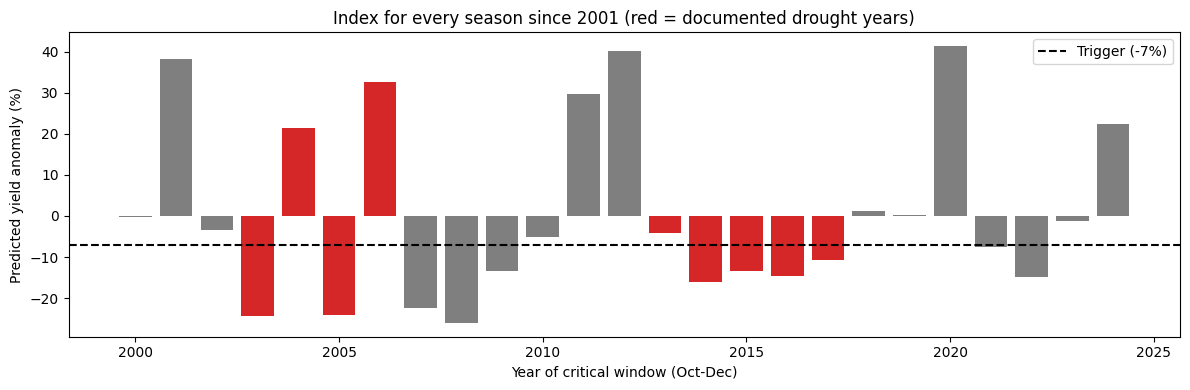

Documented drought years: payout in 67% of district-seasons (42 of 63)
Other years: payout in 35% of district-seasons (39 of 112)

By year:
             index  districts_paid  drought
window_year                                
2000          -0.3               2    False
2001          38.1               0    False
2002          -3.4               2    False
2003         -24.2               7     True
2004          21.3               1     True
2005         -24.1               7     True
2006          32.7               0     True
2007         -22.5               7    False
2008         -26.0               7    False
2009         -13.3               7    False
2010          -5.2               3    False
2011          29.7               0    False
2012          40.0               0    False
2013          -4.1               2     True
2014         -16.0               7     True
2015         -13.4               7     True
2016         -14.6               5     True
2017         -10.7      

In [ ]:
hist = sat.dropna(subset=FEATURES).copy()
hist['index'] = best.predict(hist[FEATURES].to_numpy())
hist['window_year'] = hist['season'] - 1
hist['pays'] = hist['index'] <= TRIGGER
hist['drought_year'] = hist['window_year'].isin(DROUGHT_YEARS)

by_year = hist.groupby('window_year').agg(index=('index', 'mean'), districts_paid=('pays', 'sum'))

plt.figure(figsize=(12, 4))
plt.bar(by_year.index, by_year['index'],
        color=['tab:red' if y in DROUGHT_YEARS else 'tab:grey' for y in by_year.index])
plt.axhline(TRIGGER, ls='--', color='black', label=f'Trigger ({TRIGGER:.0f}%)')
plt.xlabel('Year of critical window (Oct-Dec)'); plt.ylabel('Predicted yield anomaly (%)')
plt.title('Index for every season since 2001 (red = documented drought years)')
plt.legend(); plt.tight_layout(); plt.show()

for label, g in [('Documented drought years', hist[hist['drought_year']]),
                 ('Other years', hist[~hist['drought_year']])]:
    print(f'{label}: payout in {g["pays"].mean():.0%} of district-seasons ({g["pays"].sum()} of {len(g)})')

print('\nBy year:')
print(by_year.assign(drought=by_year.index.isin(DROUGHT_YEARS)).round(1).to_string())

## 11. Export for the backend
Saves the model (coefficients, scaler, thresholds), the 21 calibration district-seasons, and the index for every
district-season since 1982. A final check confirms the exported numbers reproduce the fitted model.

In [ ]:
EXPORT_DIR = f'{DATA_DIR}/export'
os.makedirs(EXPORT_DIR, exist_ok=True)

scaler = best.named_steps['scale']

# 1. Model and summary numbers
model_export = {
    'model': 'Ridge',
    'features': FEATURES,
    'scaler_mean': scaler.mean_.tolist(),
    'scaler_scale': scaler.scale_.tolist(),
    'coefficients': ridge.coef_.tolist(),
    'intercept': float(ridge.intercept_),
    'alpha': float(ridge.alpha_),
    'trigger': TRIGGER,
    'exit': EXIT,
    'low_yield_threshold': LOW_YIELD_THRESHOLD,
    'hit_rate': float(best_row.hit_rate),
    'false_payout_rate': float(best_row.false_payout_rate),
    'window_months': [WIN_START_MONTH, WIN_END_MONTH],
    'drought_years': DROUGHT_YEARS,
    'validation_main': results_main.reset_index().to_dict(orient='records'),
    'validation_peak_ndvi': results_peak.reset_index().to_dict(orient='records'),
}
with open(f'{EXPORT_DIR}/model.json', 'w') as f:
    json.dump(model_export, f, indent=2)

# 2. The 21 calibration district-seasons
calib = df[['district', 'season', 'yield_kg_ha', 'yield_anom', 'rain_z', 'ndvi_z',
            'index_loo', 'payout', 'payout_if_actual', 'basis_risk']].round(4)
calib.to_csv(f'{EXPORT_DIR}/calibration.csv', index=False)

# 3. Every district-season since 1982
seasons_out = sat[['district', 'season', 'rain_mm', 'ndvi', 'rain_z', 'ndvi_z']].copy()
has_both = seasons_out['ndvi_z'].notna()
seasons_out.loc[has_both, 'index'] = best.predict(seasons_out.loc[has_both, FEATURES].to_numpy())
seasons_out['payout'] = payout_fraction(seasons_out['index'])
seasons_out['window_year'] = seasons_out['season'] - 1
seasons_out['drought_year'] = seasons_out['window_year'].isin(DROUGHT_YEARS)
seasons_out.round(4).to_csv(f'{EXPORT_DIR}/seasons.csv', index=False)

# Check: the saved numbers alone reproduce the model's predictions
m = model_export
Xs = (df[FEATURES].to_numpy() - np.array(m['scaler_mean'])) / np.array(m['scaler_scale'])
manual = Xs @ np.array(m['coefficients']) + m['intercept']
assert np.allclose(manual, best.predict(df[FEATURES].to_numpy())), 'Export does not reproduce the model'

print('Export check passed: saved coefficients reproduce the model exactly\n')
for fn in ['model.json', 'calibration.csv', 'seasons.csv']:
    print(f'{fn}: {os.path.getsize(f"{EXPORT_DIR}/{fn}") / 1024:.1f} KB')
print(f'\nseasons.csv: {len(seasons_out)} rows, {seasons_out["index"].notna().sum()} with an index (2001 onward)')

Export check passed: saved coefficients reproduce the model exactly

model.json: 3.1 KB
calibration.csv: 1.5 KB
seasons.csv: 17.5 KB

seasons.csv: 308 rows, 175 with an index (2001 onward)


## 12. Deployment option: web dashboard and API

The exported model (Section 11) is served by a working MVP in the project repository
(https://github.com/JokMaker/parametric-drought-simulator):

- **API (FastAPI):** loads `model.json`, `calibration.csv` and `seasons.csv`, applies the saved scaler
  and coefficients, and serves `/api/model`, `/api/simulate`, `/api/history`, `/api/basis-risk` and
  `/api/seasons`. Interactive **Swagger UI** at `http://localhost:8000/docs`.
- **Dashboard (Next.js):** Overview, District Explorer (payout and the reason for it), Drought History
  and Basis Risk.
- **Run:** `docker compose up --build` from the repository root, then open `http://localhost:3000`.
- **Checks:** backend tests confirm the API reproduces this notebook's results (index formula on all
  175 district-seasons, hit and false payout rates, drought-year totals, basis risk).

**Swagger UI**

![API documentation](https://raw.githubusercontent.com/JokMaker/parametric-drought-simulator/main/docs/screenshots/api-docs.png)

**District Explorer: Rwamagana, Season A 2023 (84% payout)**

![District Explorer](https://raw.githubusercontent.com/JokMaker/parametric-drought-simulator/main/docs/screenshots/explorer-rwamagana-2023.png)

**Drought History**

![Drought History](https://raw.githubusercontent.com/JokMaker/parametric-drought-simulator/main/docs/screenshots/drought-history.png)